# A year-over-year model with terms

Build the ratio model from [PR #2840](https://github.com/pymc-labs/pymc-marketing/pull/2840) with terms.
Read [Introduction to terms](introduction_terms.ipynb) first.
Run the cells in order.
Use vector plots and compact dataset summaries to keep the saved notebook small.

The calendar and model follow the source example.
The spend simulation is simpler.
This notebook shows model construction, fitting, contributions, and a held-out forecast.
The source includes a larger benchmark study.

**Warning:** The API in `pymc_marketing.experimental.terms` is experimental and can change.

## 1. Model the ratio, not the level

Let `r(t)` identify the reference week for week `t`.
For unit `u`, divide the current KPI by its observed reference value:

$$z_{u,t} = \frac{y_{u,t}}{y_{u,r(t)}}.$$

Use this mean for the ratio:

$$\mu_{u,t}=g_u+\sum_c[f_{c,u,t}-f_{c,u,r(t)}]+\sum_j\gamma_j[x_{j,u,t}-x_{j,u,r(t)}].$$

Here, `g` is a growth factor.
A factor of 1 means no change.
The function `f` applies adstock, then saturation.
Each driver enters as its current value minus its reference value.

If the paired seasonal shapes match, the reference level carries the seasonality.
No Fourier term is necessary for this model.
The ratio mean is a first-order approximation to a multiplicative level model.
This approximation assumes small media and control effects and a growth factor near one.

## 2. Match the reference weeks

Use six cycles of 52 weeks.
These are fixed-length cycles, not ISO years.
Reserve the last cycle for the forecast.

In [1]:
from itertools import pairwise

import matplotlib as mpl
import numpy as np
import pandas as pd
import xarray as xr

rng = np.random.default_rng(42)

In [2]:
%matplotlib inline
%config InlineBackend.figure_formats = ["svg"]
mpl.rcParams["svg.fonttype"] = "none"
xr.set_options(display_style="text");

In [3]:
from IPython.core.pylabtools import print_figure
from matplotlib.figure import Figure

svg = get_ipython().display_formatter.formatters["image/svg+xml"]
svg.for_type(Figure, lambda figure: print_figure(figure, fmt="svg").replace("\n", " "));

In [4]:
period = 52
n_dates = 6 * period
cutoff = n_dates - period
l_max = 8
history_dates = pd.date_range("2019-01-07", periods=n_dates, freq="W-MON")

Set one holiday position per cycle.
The positions start at zero.
Include the week before and the week after each holiday.

In [5]:
holiday_positions = np.array([12, 13, 15, 14, 12, 13])
holidays = period * np.arange(6) + holiday_positions
holiday_weeks = np.add.outer(holidays, [-1, 0, 1]).ravel()
pad = 1

Start with a lag of 52 weeks.
The first cycle has no reference.

In [6]:
reference = np.arange(n_dates) - period
current_all = np.arange(period, n_dates)

Rotate the segment that contains the old and new holiday windows.
A rotation keeps each prior week once.
Moving only the holiday window would duplicate some reference weeks.

In [7]:
for prior, current in pairwise(holidays):
    shift = current - period - prior
    segment = np.arange(
        min(prior, current - period) - pad,
        max(prior, current - period) + pad + 1,
    )
    reference[segment + period] = np.roll(segment, shift)

Make sure each eligible prior week occurs once.
Also make sure each reference precedes its current week.

In [8]:
np.testing.assert_array_equal(
    np.sort(reference[current_all]), np.arange(n_dates - period)
)
np.testing.assert_array_less(-1, reference[current_all])
np.testing.assert_array_less(reference[current_all], current_all)

Make sure holiday weeks match holiday weeks.
The same rule applies to ordinary weeks.

In [9]:
np.testing.assert_array_equal(
    np.isin(current_all, holiday_weeks),
    np.isin(reference[current_all], holiday_weeks),
)

Read the week pairs near the second holiday.
The rotation is specific to this fixed calendar.
The source explains checks for more general event calendars.

In [10]:
pairs = pd.DataFrame(
    {
        "Current position": np.arange(period),
        "Reference position": reference[period : 2 * period],
    }
)
pairs.iloc[9:19]

,Current position,Reference position
9,9,9
10,10,10
11,11,14
12,12,11
13,13,12
14,14,13
15,15,15
16,16,16
17,17,17
18,18,18


## 3. Make the full input history

Use four units and three channels.
The sponsorship plan is constant within each unit.
The other plans change each week.

In [11]:
units = ["north", "south", "east", "west"]
channels = ["tv", "search", "sponsorship"]
common = rng.normal(0, 0.5, size=(n_dates, len(units), 1))
individual = rng.normal(0, 0.7, size=(n_dates, len(units), len(channels)))
spend_raw = np.logaddexp(0, common + individual)

In [12]:
spend_raw[:, :, 2] = rng.uniform(0.5, 2, size=len(units))
discount = rng.beta(1.2, 6, size=(n_dates, len(units), 1))

Put the complete input series on `history_date`.
The model will use `date` for the selected ratio observations.
The two dimensions have different lengths.

In [13]:
coords = {
    "history_date": history_dates,
    "unit": units,
    "channel": channels,
    "control": ["discount"],
}

In [14]:
inputs = xr.Dataset(
    {
        "spend": (("history_date", "unit", "channel"), spend_raw),
        "discount": (("history_date", "unit", "control"), discount),
    },
    coords=coords,
)

Divide each channel by its training maximum across units.
Keep the same scales for the forecast.
Terms do not scale data automatically.

In [15]:
channel_scale = (
    inputs["spend"].isel(history_date=slice(0, cutoff)).max(("history_date", "unit"))
)
inputs["spend"] = inputs["spend"] / channel_scale
inputs

<xarray.Dataset> Size: 43kB
Dimensions:       (history_date: 312, unit: 4, channel: 3, control: 1)
Coordinates:
  * history_date  (history_date) datetime64[us] 2kB 2019-01-07 ... 2024-12-23
  * unit          (unit) <U5 80B 'north' 'south' 'east' 'west'
  * channel       (channel) <U11 132B 'tv' 'search' 'sponsorship'
  * control       (control) <U8 32B 'discount'
Data variables:
    spend         (history_date, unit, channel) float64 30kB 0.2068 ... 0.7364
    discount      (history_date, unit, control) float64 10kB 0.09179 ... 0.02534

Plot the scaled spend.
The flat sponsorship plan will be important later.

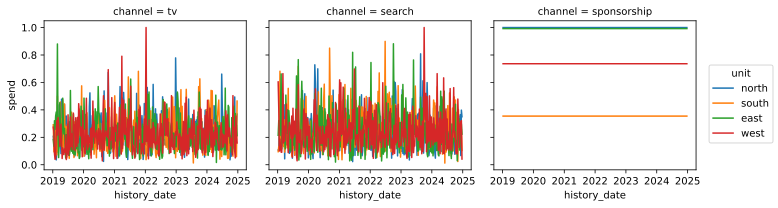

In [16]:
inputs["spend"].plot.line(x="history_date", hue="unit", col="channel", figsize=(10, 3));

## 4. Simulate the KPI

Use known parameters to simulate the ratio model with NumPy.
The media parameters are shared across units.
Each unit has its own growth factor and noise scale.

In [17]:
alpha_true = np.array([0.55, 0.25, 0.40])
lam_true = np.array([2.5, 4.0, 3.0])
beta_true = np.array([0.13, 0.08, 0.06])
growth_true = np.array([1.03, 1.00, 0.98, 1.05])
control_true = np.array([0.18])
noise_true = np.array([0.030, 0.035, 0.028, 0.032])

Normalize the eight geometric lag weights for each channel.

In [18]:
weights = alpha_true[:, None] ** np.arange(l_max)
weights = weights / weights.sum(axis=1, keepdims=True)

Apply adstock to the complete spend series.
The series starts with zero earlier spend.

In [19]:
spend_values = inputs["spend"].values
adstocked_true = np.zeros_like(spend_values)
for lag in range(l_max):
    adstocked_true[lag:] += spend_values[: n_dates - lag] * weights[:, lag]

Apply logistic saturation after adstock.
Keep the linear discount effects separate.

In [20]:
media_true = beta_true * np.tanh(lam_true * adstocked_true / 2)
control_effect_true = (discount * control_true).sum(axis=-1)

Select the current and reference responses only after these transforms.
Add their differences to the growth factor.

In [21]:
reference_all = reference[current_all]
mean_ratio_true = growth_true + (
    media_true[current_all] - media_true[reference_all]
).sum(axis=-1)
mean_ratio_true += control_effect_true[current_all] - control_effect_true[reference_all]

Add independent Normal noise on the ratio scale.
Make sure this simulated draw is positive.
Do not clip or replace negative draws.

In [22]:
ratio_draw = mean_ratio_true + rng.normal(size=mean_ratio_true.shape) * noise_true
np.testing.assert_array_less(0, ratio_draw)

Make a seasonal first cycle.
Give its holiday a three-week profile.

In [23]:
week = np.arange(period)
season = 1 + 0.45 * np.sin(2 * np.pi * (week - 8) / period)
season += 0.18 * np.cos(4 * np.pi * week / period)
season[holiday_positions[0] + np.array([-1, 0, 1])] *= [1.15, 1.55, 1.10]
unit_size = np.array([1000, 700, 1350, 900])

Multiply each later ratio by its observed reference level.
This carries the seasonal shape and holiday through the reference map.

In [24]:
levels = np.empty((n_dates, len(units)))
levels[:period] = season[:, None] * unit_size
for row, current in enumerate(current_all):
    levels[current] = levels[reference[current]] * ratio_draw[row]

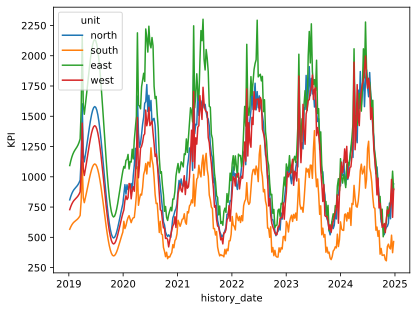

In [25]:
kpi = xr.DataArray(
    levels,
    dims=("history_date", "unit"),
    coords={"history_date": history_dates, "unit": units},
    name="KPI",
)
kpi.plot.line(x="history_date", hue="unit");

The simulated KPI follows the ratio model by construction.
This example is a self-consistency study, not evidence that this model beats a level model.

## 5. Label the ratio observations

Start eight weeks after the first cycle.
This excludes the early adstock transient from the reference side of each fitted pair.

In [26]:
positions = np.arange(period + l_max, n_dates)
data = inputs.assign_coords(date=history_dates[positions])
data["current"] = ("date", positions)
data["reference"] = ("date", reference[positions])

Select KPI values with labeled index arrays.
Keep the current `date` labels on each pair.
Remove the selected `history_date` coordinate before division.

In [27]:
current_kpi = kpi.isel(history_date=data["current"]).drop_vars("history_date")
reference_kpi = kpi.isel(history_date=data["reference"]).drop_vars("history_date")
data["ratio"] = current_kpi / reference_kpi

Make sure the observed ratios reproduce the simulated draw.

In [28]:
np.testing.assert_allclose(data["ratio"], ratio_draw[positions - period])

Fit all ratio observations before the last cycle.
The held-out ratios are not inputs to the fit.

In [29]:
train = data.isel(date=slice(None, -period))
future = data.isel(date=slice(-period, None)).drop_vars("ratio")
train

<xarray.Dataset> Size: 54kB
Dimensions:       (history_date: 312, unit: 4, channel: 3, control: 1, date: 200)
Coordinates:
  * history_date  (history_date) datetime64[us] 2kB 2019-01-07 ... 2024-12-23
  * unit          (unit) <U5 80B 'north' 'south' 'east' 'west'
  * channel       (channel) <U11 132B 'tv' 'search' 'sponsorship'
  * control       (control) <U8 32B 'discount'
  * date          (date) datetime64[us] 2kB 2020-03-02 2020-03-09 ... 2023-12-25
Data variables:
    spend         (history_date, unit, channel) float64 30kB 0.2068 ... 0.7364
    discount      (history_date, unit, control) float64 10kB 0.09179 ... 0.02534
    current       (date) int64 2kB 60 61 62 63 64 65 ... 254 255 256 257 258 259
    reference     (date) int64 2kB 8 9 10 14 11 12 ... 202 203 204 205 206 207
    ratio         (date, unit) float64 6kB 0.9413 0.9879 0.9713 ... 0.9574 1.106

Read the input names and dimensions:

| Variable | Dimensions | Role |
| --- | --- | --- |
| `spend` | `history_date, unit, channel` | Full scaled media history. |
| `discount` | `history_date, unit, control` | Full discount history. |
| `current` | `date` | Current positions in the full history. |
| `reference` | `date` | Matching reference positions. |
| `ratio` | `date, unit` | Observed target. |

The full input history includes the known future spend and discount schedule.
Adstock uses earlier spend only.
The model does not use future KPI values.

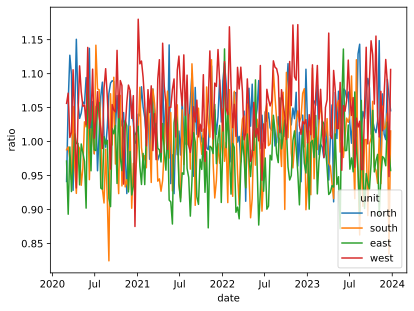

In [30]:
train["ratio"].plot.line(x="date", hue="unit");

## 6. Define the full-history media response

Use the same component priors as the source model.
Keep one set of curve parameters per channel, shared across units.

In [31]:
from pymc_extras.prior import Prior

from pymc_marketing.mmm import GeometricAdstock, LogisticSaturation

In [32]:
adstock = GeometricAdstock(l_max=l_max).with_default_prior_dims(("channel",))
saturation = LogisticSaturation(
    priors={"beta": Prior("HalfNormal", sigma=0.2)}
).with_default_prior_dims(("channel",))

The `>>` pipeline uses `date` as its time axis.
Here, the complete series uses `history_date`.
Set that axis in a short response function.

In [33]:
from typing import Any

from pymc_marketing.terms import Transform

In [34]:
def media_response(value: Any) -> Any:
    """Apply the media components along the full history."""
    adstocked = adstock.apply(value, core_dim="history_date")
    return saturation.apply(adstocked, core_dim="history_date")

Apply the response function to the named input.
This term is the full response, before any week selection.

In [35]:
from pymc_marketing.experimental.terms import Data

full_media = Transform(Data("spend"), media_response)

The explicit channel dimensions are important here.
A direct component call does not infer the non-time dimensions as the `>>` pipeline does.

## 7. Select the current and reference responses

Make a small selection term.
Its inputs are a full-history term and a position term.
It selects values; it does not fit a separate response curve.

In [36]:
from dataclasses import dataclass

from pymc_marketing.terms import ModelTerm, build_param

In [37]:
@dataclass
class At(ModelTerm):
    """Select full-history values with labeled positions."""

    value: ModelTerm
    index: ModelTerm

    def create_variable(self) -> Any:
        """Return values at the selected history positions."""
        positions = build_param(self.index).astype("int64")
        return build_param(self.value).isel(history_date=positions)

`Data` stores numeric inputs as floating-point values.
Convert positions to integers before selection.
The position term supplies the selected `date` dimension.

In [38]:
current = Data("current")
previous = Data("reference")

Reuse the same `full_media` object for the two selections.
This shares one set of media parameters.

In [39]:
current_media = At(full_media, current).named("current_media")
reference_media = At(full_media, previous).named("reference_media")

Subtract the reference response from the current response.
Do not put the spend difference inside saturation.
Each selected response already has its own adstock history.

In [40]:
media_change = (current_media - reference_media).named("media_change")

Select the discount values with the same positions.

In [41]:
full_discount = Data("discount")
current_discount = At(full_discount, current)
reference_discount = At(full_discount, previous)
discount_change = current_discount - reference_discount

## 8. Add growth, controls, and the likelihood

Set a growth-factor prior for each unit.
The prior is centered at no change.

In [42]:
from pymc_marketing.terms import Parameter

growth = Parameter("growth", Prior("Normal", mu=1, sigma=0.15, dims="unit"))

Set one coefficient per control, shared across units.
Multiply each discount contrast by this coefficient.

In [43]:
control_coef = Parameter(
    "control_coef", Prior("Normal", mu=0, sigma=0.5, dims="control")
)
control_change = (discount_change * control_coef).sum("control").named("control_change")

Add the terms to form the ratio mean.

In [44]:
ratio_mean = (growth + media_change.sum("channel") + control_change).named("ratio_mean")

Use Normal observation noise on the ratio scale.
Give each unit its own noise scale.

In [45]:
noise_prior = Prior("HalfNormal", sigma=0.1, dims="unit")
likelihood = Prior("Normal", sigma=noise_prior)

Connect the mean and likelihood to the observed ratio.
Then build the model with the training dataset.

In [46]:
from pymc_marketing.experimental.terms import GAM, Equation

ratio = Equation(observed="ratio", mu=ratio_mean, likelihood=likelihood)
gam = GAM(ratio)
gam.build_model(train);

Show the parameter dimensions.
Media parameters vary by channel, not by unit.
Growth and noise vary by unit.

In [47]:
from pymc_extras.printing import model_table

model_table(gam.model)

          Variable  Expression                                            Dimensions                               
───────────────────────────────────────────────────────────────────────────────────────────────────────────────────
         current =  Data                                                  date[200]                                
           spend =  Data                                                  history_date[312] × unit[4] × channel[3] 
       reference =  Data                                                  date[200]                                
        discount =  Data                                                  history_date[312] × unit[4] × control[1] 
                                                                                                                   
          growth ~  Normal(1, 0.15)                                       unit[4]                                  
   adstock_alpha ~  Beta(1, 3)                                            channel[3]                               
  saturation_lam ~  Gamma(3, <constant>)                                  channel[3]                               
 saturation_beta ~  HalfNormal(0, 0.2)                                    channel[3]                               
    control_coef ~  Normal(0, 0.5)                                        control[1]                               
     ratio_sigma ~  HalfNormal(0, 0.1)                                    unit[4]                                  
                                                                          Parameter count = 18                     
                                                                                                                   
   current_media =  f(saturation_beta, saturation_lam, adstock_alpha)     channel[3] × unit[4] × date[200]         
 reference_media =  f(saturation_beta, saturation_lam, adstock_alpha)     channel[3] × unit[4] × date[200]         
    media_change =  f(saturation_beta, saturation_lam, adstock_alpha)     channel[3] × unit[4] × date[200]         
  control_change =  f(control_coef)                                       date[200] × unit[4]                      
      ratio_mean =  f(growth, control_coef, saturation_beta,              unit[4] × date[200]                      
                    saturation_lam, adstock_alpha)                                                                 
                                                                                                                   
           ratio ~  Unknown(Normal(f(growth, control_coef,                date[200] × unit[4]                      
                    saturation_beta, saturation_lam, adstock_alpha),                                               
                    ratio_sigma))

The table can show `Unknown(...)` around the Normal likelihood.
This is a PyMC printing limitation, not a different likelihood.
Graphviz shows the dimension reorder as `Transpose`.
The notation `f(...)` represents the combined mean.

Show the graph below the table.

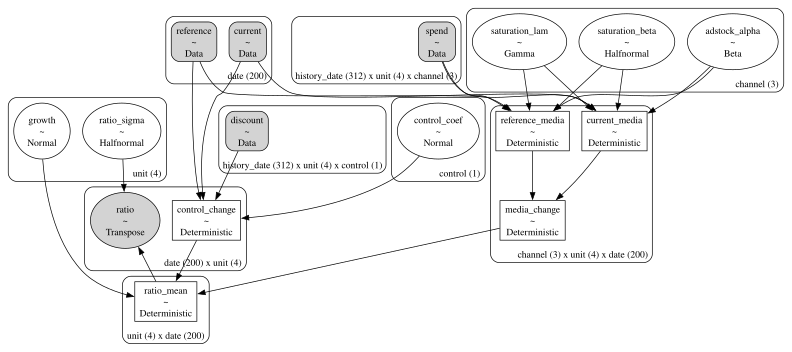

In [48]:
import pymc as pm

graph = pm.model_to_graphviz(gam.model)
graph.graph_attr["size"] = "11,7"
graph

## 9. Compare the graph with the NumPy simulation

Fix the parameters at their known values.
This check tests the full-history transform and the selected week pairs.

In [49]:
truth = {
    "adstock_alpha": alpha_true,
    "saturation_lam": lam_true,
    "saturation_beta": beta_true,
    "growth": growth_true,
    "control_coef": control_true,
    "ratio_sigma": noise_true,
}

In [50]:
fixed_model = pm.do(gam.model, truth)
fixed = pm.sample_prior_predictive(
    model=fixed_model,
    draws=1,
    var_names=["current_media", "reference_media", "ratio_mean"],
    random_seed=43,
)
fixed_draw = fixed["prior"].to_dataset().isel(chain=0, draw=0)

Sampling: []


Compare the selected media responses before summing channels.

In [51]:
for name, index in (("current_media", "current"), ("reference_media", "reference")):
    np.testing.assert_allclose(
        fixed_draw[name].transpose("date", "unit", "channel"),
        media_true[train[index].values],
        rtol=1e-12,
        atol=1e-12,
    )

Compare the complete mean, including growth and controls.

In [52]:
np.testing.assert_allclose(
    fixed_draw["ratio_mean"].transpose("date", "unit"),
    mean_ratio_true[train["current"].values - period],
    rtol=1e-12,
    atol=1e-12,
)
print("The graph agrees with the independent NumPy calculation.")

The graph agrees with the independent NumPy calculation.


## 10. Read the prior predictions

Simulate ratios before fitting.
This call does not change the fitted model.

In [53]:
prior = gam.sample_prior_predictive(train, draws=500, random_seed=44)
prior

Sampling: [adstock_alpha, control_coef, growth, ratio, ratio_sigma, saturation_beta, saturation_lam]


<xarray.DataTree>
Group: /
├── Group: /prior
│       Dimensions:          (chain: 1, draw: 500, channel: 3, control: 1, unit: 4,
│                             date: 200)
│       Coordinates:
│         * chain            (chain) int64 8B 0
│         * draw             (draw) int64 4kB 0 1 2 3 4 5 6 ... 494 495 496 497 498 499
│         * channel          (channel) <U11 132B 'tv' 'search' 'sponsorship'
│         * control          (control) <U8 32B 'discount'
│         * unit             (unit) <U5 80B 'north' 'south' 'east' 'west'
│         * date             (date) datetime64[us] 2kB 2020-03-02 ... 2023-12-25
│       Data variables:
│           adstock_alpha    (chain, draw, channel) float64 12kB 0.2883 0.5884 ... 0.222
│           saturation_beta  (chain, draw, channel) float64 12kB 0.1138 ... 0.1353
│           control_coef     (chain, draw, control) float64 4kB 1.52 ... -0.07055
│           growth           (chain, draw, unit) float64 16kB 1.082 1.084 ... 0.9772
│           ratio_sigma      (chain, draw, unit) float64 16kB 0.05327 ... 0.01392
│           current_media    (chain, draw, channel, unit, date) float64 10MB 0.03159 ...
│           reference_media  (chain, draw, channel, unit, date) float64 10MB 0.0366 ....
│           media_change     (chain, draw, channel, unit, date) float64 10MB -0.00501...
│           saturation_lam   (chain, draw, channel) float64 12kB 4.593 5.332 ... 1.46
│           ratio_mean       (chain, draw, unit, date) float64 3MB 0.8722 ... 1.035
│           control_change   (chain, draw, date, unit) float64 3MB -0.1998 ... -0.000...
│       Attributes:
│           created_at:                 2026-10-19T10:03:36.848861+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.2.0
│           creation_library_language:  Python
│           inference_library:          pymc
│           inference_library_version:  6.3.2
│           sample_dims:                ['chain', 'draw']
├── Group: /prior_predictive
│       Dimensions:  (chain: 1, draw: 500, date: 200, unit: 4)
│       Coordinates:
│         * chain    (chain) int64 8B 0
│         * draw     (draw) int64 4kB 0 1 2 3 4 5 6 7 ... 493 494 495 496 497 498 499
│         * date     (date) datetime64[us] 2kB 2020-03-02 2020-03-09 ... 2023-12-25
│         * unit     (unit) <U5 80B 'north' 'south' 'east' 'west'
│       Data variables:
│           ratio    (chain, draw, date, unit) float64 3MB 0.8958 1.697 ... 1.101 1.033
│       Attributes:
│           created_at:                 2026-10-19T10:03:36.850975+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.2.0
│           creation_library_language:  Python
│           inference_library:          pymc
│           inference_library_version:  6.3.2
│           sample_dims:                ['chain', 'draw']
└── Group: /observed_data
        Dimensions:  (date: 200, unit: 4)
        Coordinates:
          * date     (date) datetime64[us] 2kB 2020-03-02 2020-03-09 ... 2023-12-25
          * unit     (unit) <U5 80B 'north' 'south' 'east' 'west'
        Data variables:
            ratio    (date, unit) float64 6kB 0.9413 0.9879 0.9713 ... 0.9574 1.106
        Attributes:
            created_at:                 2026-10-19T10:03:36.851584+00:00
            creation_library:           ArviZ
            creation_library_version:   1.2.0
            creation_library_language:  Python
            inference_library:          pymc
            inference_library_version:  6.3.2
            sample_dims:                []

Compare the prior ratio range with the training data.
These summaries combine dates and units.

In [54]:
prior_range = prior["prior_predictive"]["ratio"].quantile(
    [0.03, 0.5, 0.97], dim=("chain", "draw", "date", "unit")
)
observed_range = train["ratio"].quantile([0.03, 0.5, 0.97], dim=("date", "unit"))

In [55]:
pd.DataFrame(
    {
        "Prior predictive ratio": prior_range.values,
        "Observed ratio": observed_range.values,
    },
    index=["3%", "Median", "97%"],
).round(3)

,Prior predictive ratio,Observed ratio
3%,0.606,0.903
Median,0.999,1.016
97%,1.397,1.127


The Normal likelihood can give negative ratios.
It is not a positive-support likelihood.
A nonpositive or missing reference KPI cannot define this ratio target.

## 11. Fit the model and read diagnostics

Fit all training ratio observations with four chains.
The forecast cycle stays outside the likelihood.

In [56]:
idata = gam.fit(
    train,
    chains=4,
    tune=2000,
    draws=2000,
    target_accept=0.95,
    nuts_sampler="nutpie",
    random_seed=45,
)

NUTS[nutpie]: [growth, adstock_alpha, saturation_lam, saturation_beta, control_coef, ratio_sigma]


Output()

In [57]:
import arviz as az

posterior = idata["posterior"].to_dataset()
media_names = ["adstock_alpha", "saturation_lam", "saturation_beta"]
parameter_names = [*media_names, "growth", "control_coef", "ratio_sigma"]
az.summary(idata, var_names=parameter_names)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
adstock_alpha[tv],0.572,0.056,0.48,0.66,6186,5645,1.00,0.00071,0.00053
adstock_alpha[search],0.256,0.0494,0.18,0.33,6607,5327,1.00,0.00061,0.00044
adstock_alpha[sponsorship],0.251,0.193,0.018,0.62,9528,4525,1.00,0.0017,0.0012
saturation_lam[tv],3.32,1.42,1.3,5.8,1010,1203,1.00,0.042,0.03
saturation_lam[search],4.59,0.92,3.1,6,3548,2672,1.00,0.015,0.011
saturation_lam[sponsorship],3.01,1.83,0.79,6.3,10939,4334,1.00,0.016,0.018
saturation_beta[tv],0.13,0.057,0.077,0.24,985,1126,1.00,0.0019,0.003
saturation_beta[search],0.084,0.0097,0.072,0.1,3400,2746,1.00,0.00022,0.00034
saturation_beta[sponsorship],0.157,0.118,0.013,0.38,4574,2741,1.00,0.0013,0.0011
growth[north],1.03049,0.00217,1,1,12719,5764,1.00,1.9e-05,1.4e-05


Read divergences, R-hat, and effective sample size before you interpret the fit.

In [58]:
parameter_draws = posterior[parameter_names]
diagnostics = pd.Series(
    {
        "Divergences": int(idata["sample_stats"]["diverging"].sum()),
        "Maximum R-hat": float(az.rhat(parameter_draws).to_array().max()),
        "Minimum bulk ESS": float(
            az.ess(parameter_draws, method="bulk").to_array().min()
        ),
    },
    name="Sampling diagnostics",
)
diagnostics.to_frame()

,Sampling diagnostics
Divergences,0.000000
Maximum R-hat,1.002660
Minimum bulk ESS,985.660447


Compare the media parameters with their known values.
Keep the 94% intervals visible.
The known values have the same input scale as the fitted parameters.

In [59]:
media_mean = posterior[media_names].mean(("chain", "draw")).to_array("parameter")
media_interval = az.hdi(posterior[media_names], prob=0.94).to_array("parameter")

In [60]:
media_truth = xr.DataArray(
    np.stack([alpha_true, lam_true, beta_true]),
    dims=("parameter", "channel"),
    coords={"parameter": media_names, "channel": channels},
)

In [61]:
recovery = xr.Dataset(
    {
        "Mean": media_mean,
        "94% lower": media_interval.sel(ci_bound="lower", drop=True),
        "94% upper": media_interval.sel(ci_bound="upper", drop=True),
        "Known value": media_truth,
    }
)
recovery.to_dataframe().round(3)

Mean  94% lower  94% upper  Known value
channel     parameter                                                
tv          adstock_alpha    0.572      0.464      0.675         0.55
            saturation_lam   3.317      0.846      5.853         2.50
            saturation_beta  0.130      0.064      0.236         0.13
search      adstock_alpha    0.256      0.167      0.353         0.25
            saturation_lam   4.593      2.773      6.233         4.00
            saturation_beta  0.084      0.068      0.101         0.08
sponsorship adstock_alpha    0.251      0.000      0.611         0.40
            saturation_lam   3.012      0.321      6.343         3.00
            saturation_beta  0.157      0.000      0.369         0.06

Compare posterior and prior standard deviations for each media parameter.
A value near 1 indicates little change in marginal uncertainty.
It does not establish causal identification.

In [62]:
sd_ratios = {
    name: posterior[name].std(("chain", "draw"))
    / prior["prior"][name].std(("chain", "draw"))
    for name in media_names
}
xr.Dataset(sd_ratios).to_dataframe().round(3)

,adstock_alpha,saturation_lam,saturation_beta
channel,,,
tv,0.286,0.835,0.459
search,0.275,0.547,0.076
sponsorship,1.017,1.072,1.006


## 12. Read the fitted ratio predictions

Predict the training observations without automatic history.
The supplied `history_date` series already contains the complete history.

In [63]:
in_sample = gam.sample_posterior_predictive(
    train,
    var_names=["ratio"],
    include_last_observations=False,
    random_seed=46,
    progressbar=False,
)

Sampling: [ratio]


In [64]:
training_interval = az.hdi(in_sample["ratio"], prob=0.94)
training_mean = in_sample["ratio"].mean(("chain", "draw"))

In [65]:
training_lines = xr.Dataset(
    {
        "Observed": train["ratio"],
        "Mean": training_mean,
        "94% lower": training_interval.sel(ci_bound="lower", drop=True),
        "94% upper": training_interval.sel(ci_bound="upper", drop=True),
    }
)

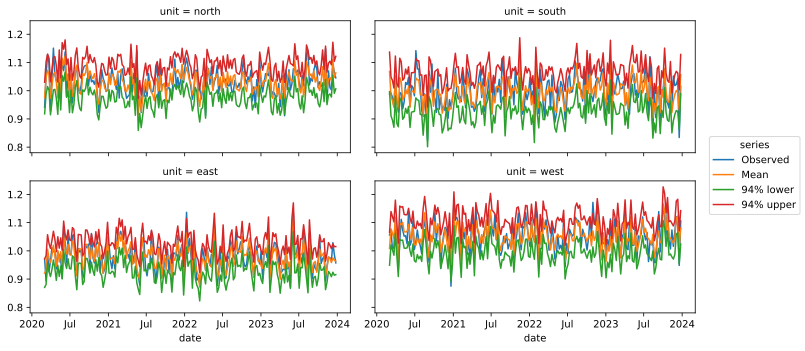

In [66]:
training_lines.to_array("series").plot.line(
    x="date", hue="series", col="unit", col_wrap=2, figsize=(10, 5)
);

The interval limits include observation noise.
Read the current output instead of assuming that all intervals contain the data.

## 13. Convert the contributions to KPI units

Multiply each ratio component by its own observed reference KPI.
Do this before you sum dates or units.

In [67]:
reference_train = reference_kpi.sel(date=train["date"])
observed_train = current_kpi.sel(date=train["date"])
predicted_level = posterior["ratio_mean"] * reference_train

First, keep the contrast basis.
The media terms describe changes from the reference plan, not total channel levels.

In [68]:
baseline_kpi = posterior["growth"] * reference_train
media_change_kpi = posterior["media_change"] * reference_train
control_change_kpi = posterior["control_change"] * reference_train
contrast_total = baseline_kpi + media_change_kpi.sum("channel") + control_change_kpi

Make sure these parts sum to the predicted level in every draw and week.

In [69]:
np.testing.assert_allclose(
    contrast_total.transpose(*predicted_level.dims), predicted_level, rtol=1e-12
)

Add the ratio residual in KPI units.
Make sure the result equals the observed KPI for each unit and week.

In [70]:
residual_kpi = (train["ratio"] - posterior["ratio_mean"]) * reference_train
reconstructed = (contrast_total + residual_kpi).transpose(*predicted_level.dims)
np.testing.assert_allclose(
    reconstructed, observed_train.broadcast_like(predicted_level), rtol=1e-12
)

### Read the level basis

For logistic saturation, zero spend has zero response.
Report the current media response as the channel level.
Subtract its reference response from the baseline.
This is an algebraic regrouping of the same fitted mean.

In [71]:
discount_current = (
    inputs["discount"].isel(history_date=train["current"]).drop_vars("history_date")
)
discount_reference = (
    inputs["discount"].isel(history_date=train["reference"]).drop_vars("history_date")
)
current_control = (discount_current * posterior["control_coef"]).sum("control")
previous_control = (discount_reference * posterior["control_coef"]).sum("control")

In [72]:
adjusted_baseline = (
    posterior["growth"] - posterior["reference_media"].sum("channel") - previous_control
) * reference_train
media_level_kpi = posterior["current_media"] * reference_train
control_level_kpi = current_control * reference_train

Make sure the level basis gives the same predicted KPI.
The adjusted baseline can be negative.

In [73]:
level_total = adjusted_baseline + media_level_kpi.sum("channel") + control_level_kpi
np.testing.assert_allclose(
    level_total.transpose(*predicted_level.dims), predicted_level, rtol=1e-12
)

Sum the media contributions only after the unit-week conversion.
Keep the uncertainty of the level contribution visible.

In [74]:
change_totals = media_change_kpi.sum(("date", "unit"))
level_totals = media_level_kpi.sum(("date", "unit"))
level_interval = az.hdi(level_totals, prob=0.94)

In [75]:
contributions = xr.Dataset(
    {
        "Mean change": change_totals.mean(("chain", "draw")),
        "Mean level": level_totals.mean(("chain", "draw")),
        "Level 94% lower": level_interval.sel(ci_bound="lower", drop=True),
        "Level 94% upper": level_interval.sel(ci_bound="upper", drop=True),
    }
)
contributions.to_dataframe().round(1)

,Mean change,Mean level,Level 94% lower,Level 94% upper
channel,,,,
tv,90.6,31791.5,23952.5,39551.8
search,371.8,33876.0,26196.4,42001.1
sponsorship,0.0,92712.9,2.1,236002.9


The flat sponsorship plan cancels in every fitted pair.
Make sure its contrast is zero in every posterior draw.

In [76]:
np.testing.assert_allclose(
    posterior["media_change"].sel(channel="sponsorship"), 0, atol=1e-12
)

The ratio likelihood cannot identify the sponsorship curve from a zero contrast.
Its reported level reflects its priors, scaled by the observed reference KPI.
A positive level contribution is not evidence of an identified media effect.

The other level contributions also depend on the curve and its zero-spend reference.
The closure checks verify the algebra, not the causal meaning of the components.

## 14. Forecast the last 52 weeks

Use the same full input history and new `date` rows.
Keep `history_date`, unit, and channel labels unchanged.
The forecast assumes the supplied future spend and discount schedule.

Make sure every reference KPI belongs to the training period.
The held-out KPI is used only for scoring.

In [77]:
np.testing.assert_equal("ratio" in future, False)
np.testing.assert_array_less(future["reference"].values, cutoff)
np.testing.assert_equal(int(train["reference"].min()) >= l_max - 1, True)

Predict ratios and their conditional mean.
Do not prepend history on `date`; the complete series is already on `history_date`.

In [78]:
forecast = gam.sample_posterior_predictive(
    future,
    var_names=["ratio", "ratio_mean"],
    include_last_observations=False,
    random_seed=47,
    progressbar=False,
)

Sampling: [ratio]


Multiply each predicted ratio by its observed reference KPI.
This returns the predictive distribution to KPI units.

In [79]:
reference_future = reference_kpi.sel(date=future["date"])
forecast_level = forecast["ratio"] * reference_future
actual = current_kpi.sel(date=future["date"])
forecast_mean = forecast["ratio_mean"].mean(("chain", "draw")) * reference_future

In [80]:
forecast_interval = az.hdi(forecast_level, prob=0.94)
forecast_lines = xr.Dataset(
    {
        "Observed": actual,
        "Mean": forecast_mean,
        "94% lower": forecast_interval.sel(ci_bound="lower", drop=True),
        "94% upper": forecast_interval.sel(ci_bound="upper", drop=True),
    }
)

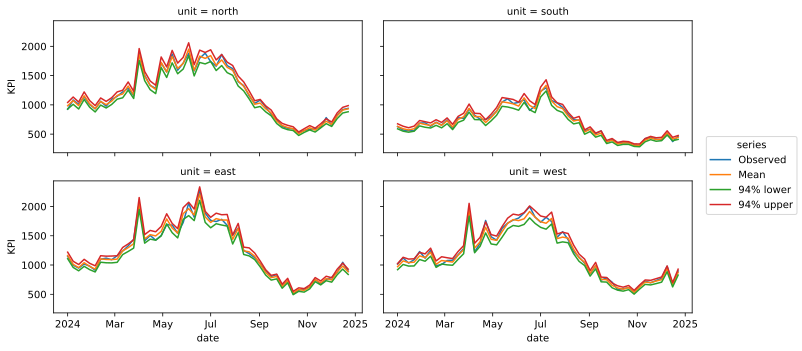

In [81]:
forecast_lines.to_array("series").rename("KPI").plot.line(
    x="date", hue="series", col="unit", col_wrap=2, figsize=(10, 5)
);

### Compare with a seasonal naive forecast

Use the training mean ratio as a growth factor.
Use the training ratio standard deviation as its noise scale.
This forecast has no media or control terms.

In [82]:
naive_growth = train["ratio"].mean("date")
naive_scale = train["ratio"].std("date", ddof=1)
naive_noise = xr.DataArray(
    rng.normal(size=forecast["ratio"].shape),
    dims=forecast["ratio"].dims,
    coords=forecast["ratio"].coords,
)
naive_level = (naive_growth + naive_scale * naive_noise) * reference_future

Score the complete predictive distributions with CRPS.
Lower CRPS is better.
Also compare root mean squared error (RMSE) and interval coverage.

In [83]:
from pymc_marketing.metrics import crps

forecasts = {"YoY terms": forecast_level, "Seasonal naive": naive_level}
crps_scores = {}
for name, draws in forecasts.items():
    samples = draws.stack(sample=("chain", "draw")).transpose("sample", "date", "unit")
    crps_scores[name] = crps(actual.values, samples.values)

In [84]:
mean_errors = {
    name: draws.mean(("chain", "draw")) - actual for name, draws in forecasts.items()
}
rmse_scores = {
    name: float(np.sqrt((error**2).mean())) for name, error in mean_errors.items()
}
intervals = {name: az.hdi(draws, prob=0.94) for name, draws in forecasts.items()}

In [85]:
coverage_scores = {}
for name, interval in intervals.items():
    lower = interval.sel(ci_bound="lower")
    upper = interval.sel(ci_bound="upper")
    coverage_scores[name] = float(((actual >= lower) & (actual <= upper)).mean())

In [86]:
pd.DataFrame(
    {"CRPS": crps_scores, "RMSE": rmse_scores, "94% coverage": coverage_scores}
).round(3)

,CRPS,RMSE,94% coverage
YoY terms,19.885,38.274,0.909
Seasonal naive,34.036,64.928,0.894


Read these scores as results for one simulated panel and one forecast window.
The observed reference levels supply much of the forecast structure.
The scores do not establish a general ranking of model types.

## 15. Keep the assumptions visible

- Use positive, nonzero reference KPI values.
- Match moving events without duplicating reference weeks.
- Apply adstock and saturation before selecting the paired weeks.
- Share the full-history media term across the two selections.
- Convert each contribution to KPI units before aggregation.
- Read the prior comparison before interpreting a flat channel's level contribution.

The reference KPI is an observation, not a noise-free baseline.
For small, independent relative level errors with equal variance, ratio error variance is approximately doubled when the expected ratio is near one.
Ratios in consecutive cycles can have negatively correlated errors.
The independent Normal likelihood does not model this correlation.

Anchoring aligns the holiday window.
It does not generally align a fixed seasonal shape beneath a moving holiday.
The simulated data here carry their shape through the map, so they favor this model.

The fitted model does not establish causal identification.
Use the [source notebook](https://github.com/pymc-labs/pymc-marketing/pull/2840) for the level-model benchmarks and fixed-shape counterexample.
The [main MMM example](experimental_mmm_api.ipynb) covers budget optimization with terms.

In [87]:
%load_ext watermark
%watermark -n -u -v -iv -w -p pymc_marketing,pytensor,nutpie

Last updated: Mon, 19 Oct 2026

Python implementation: CPython
Python version       : 3.13.9
IPython version      : 9.15.0

pymc_marketing: 1.2.0
pytensor      : 3.3.2
nutpie        : 0.16.11

IPython       : 9.15.0
arviz         : 1.2.0
matplotlib    : 3.11.1
numpy         : 2.4.6
pandas        : 3.0.5
pymc          : 6.3.2
pymc_extras   : 0.15.1
pymc_marketing: 1.2.0
xarray        : 2026.4.0

Watermark: 2.6.0

